# 02 — Audit et qualité des données
### CHU Mohammed VI — Agadir | Module Hospitalisations

**Objectif de ce notebook :**
1. Charger les 4 fichiers bruts (`patients`, `services`, `medecins`, `hospitalisations`)
2. Auditer la **complétude**, les **doublons**, et la **cohérence** (dates, âges, clés étrangères)
3. Nettoyer les données selon une stratégie documentée par colonne
4. Comparer **avant / après** avec des tableaux et des visualisations commentées
5. Exporter les fichiers nettoyés dans `data/clean/`

Ce notebook consomme les fichiers générés par `01_generation_dataset.ipynb`.

**Méthode de lecture recommandée :** chaque section technique (code) est suivie d'un court paragraphe d'interprétation qui explique comment lire le résultat et ce qu'il signifie pour la qualité du jeu de données. Les visualisations de la section 7 constituent le support à réutiliser directement dans le rapport de stage ou la soutenance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

# --- Style graphique global : cohérent, sobre, orienté rapport ---
sns.set_style("whitegrid", {"grid.linestyle": "--"})
plt.rcParams.update({
    "figure.figsize": (11, 5.5),
    "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Liberation Sans"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 16,
    "axes.labelsize": 11,
    "axes.labelcolor": "#3A3A3A",
    "axes.edgecolor": "#B0B0B0",
    "axes.linewidth": 0.8,
    "text.color": "#2B2B2B",
    "xtick.color": "#3A3A3A",
    "ytick.color": "#3A3A3A",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "grid.color": "#E3E3E3",
    "grid.linewidth": 0.7,
    "legend.frameon": False,
    "legend.fontsize": 10,
    "savefig.dpi": 150,
})

# --- Palette cohérente utilisée sur l'ensemble du notebook ---
COULEUR_AVANT = "#C0392B"      # rouge sourd : état avant nettoyage
COULEUR_APRES = "#1F8A70"      # vert profond : état après nettoyage
COULEUR_ACCENT = "#2E5090"     # bleu : indicateurs neutres / analytiques
COULEUR_NEUTRE = "#95A5A6"     # gris : éléments secondaires
PALETTE_CATEGORIELLE = ["#2E5090", "#1F8A70", "#C0392B", "#D68910", "#7D3C98", "#17A2A2", "#95A5A6"]

RAW_DIR = "../data/raw"
CLEAN_DIR = "../data/clean"
FIG_DIR = "../reports/figures"
os.makedirs(CLEAN_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


def styliser_axe(ax, titre, xlabel="", ylabel="", legende=None):
    """Applique une mise en forme cohérente (titre, axes, légende) à un graphique."""
    ax.set_title(titre, loc="left", fontsize=14, fontweight="bold", color="#1F2937")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#B0B0B0")
    ax.spines["bottom"].set_color("#B0B0B0")
    if legende:
        ax.legend(legende, frameon=False, loc="best")


def etiqueter_barres(ax, fmt="{:.1f}", **kwargs):
    """Ajoute les valeurs au-dessus/à côté de chaque barre d'un graphique."""
    for conteneur in ax.containers:
        ax.bar_label(conteneur, fmt=fmt, fontsize=9, color="#2B2B2B", padding=3, **kwargs)


print("Environnement graphique configure.")

Environnement graphique configure.


## 1. Chargement des fichiers bruts

In [2]:
df_patients = pd.read_csv(f"{RAW_DIR}/patients.csv", parse_dates=["date_naissance"])
df_services = pd.read_csv(f"{RAW_DIR}/services.csv")
df_medecins = pd.read_csv(f"{RAW_DIR}/medecins.csv")
df_hospitalisations = pd.read_csv(f"{RAW_DIR}/hospitalisations.csv", parse_dates=["date_entree", "date_sortie"])

print(f"Patients : {len(df_patients)} lignes")
print(f"Services : {len(df_services)} lignes")
print(f"Medecins : {len(df_medecins)} lignes")
print(f"Hospitalisations : {len(df_hospitalisations)} lignes")

Patients : 8160 lignes
Services : 16 lignes
Medecins : 103 lignes
Hospitalisations : 15300 lignes


## 2. Fonctions d'audit réutilisables

Ces fonctions seront appelées deux fois : une fois **avant** nettoyage, une fois **après**, pour permettre la comparaison finale.

In [3]:
def taux_completude(df, nom_table):
    """Retourne un DataFrame avec le taux de valeurs manquantes par colonne."""
    taux = (df.isna().sum() / len(df) * 100).round(2)
    resultat = taux.reset_index()
    resultat.columns = ["colonne", "taux_manquant_pct"]
    resultat.insert(0, "table", nom_table)
    return resultat


def taux_doublons(df, cle, nom_table):
    """Retourne le nombre et le taux de doublons sur une clé métier donnée."""
    n_doublons = df.duplicated(subset=[cle]).sum()
    taux = round(n_doublons / len(df) * 100, 2)
    return {"table": nom_table, "nb_doublons": int(n_doublons), "taux_doublons_pct": taux}


def audit_coherence(df_hosp, df_patients, df_services, df_medecins):
    """Retourne un dict des différents contrôles de cohérence sur hospitalisations."""
    resultats = {}

    # Dates incohérentes (sortie avant entrée)
    dates_valides = df_hosp["date_entree"].notna() & df_hosp["date_sortie"].notna()
    incoherentes = (df_hosp["date_sortie"] < df_hosp["date_entree"]) & dates_valides
    resultats["dates_incoherentes"] = int(incoherentes.sum())

    # id_service inexistant
    services_valides = set(df_services["id_service"])
    mask_service_connu = df_hosp["id_service"].notna()
    service_inconnu = mask_service_connu & (~df_hosp.loc[mask_service_connu, "id_service"].isin(services_valides))
    resultats["id_service_inconnu"] = int(service_inconnu.sum())

    # id_medecin inexistant
    medecins_valides = set(df_medecins["id_medecin"])
    mask_medecin_connu = df_hosp["id_medecin"].notna()
    medecin_inconnu = mask_medecin_connu & (~df_hosp.loc[mask_medecin_connu, "id_medecin"].isin(medecins_valides))
    resultats["id_medecin_inconnu"] = int(medecin_inconnu.sum())

    # id_patient inexistant
    patients_valides = set(df_patients["id_patient"])
    mask_patient_connu = df_hosp["id_patient"].notna()
    patient_inconnu = mask_patient_connu & (~df_hosp.loc[mask_patient_connu, "id_patient"].isin(patients_valides))
    resultats["id_patient_inconnu"] = int(patient_inconnu.sum())

    # Cohérence médecin <-> service : le médecin doit appartenir au service de l'hospitalisation
    merge_check = df_hosp.merge(
        df_medecins[["id_medecin", "id_service"]], on="id_medecin", suffixes=("", "_medecin"), how="left"
    )
    mask_les_deux_connus = merge_check["id_service"].notna() & merge_check["id_service_medecin"].notna()
    incoherence_medecin_service = mask_les_deux_connus & (
        merge_check["id_service"] != merge_check["id_service_medecin"]
    )
    resultats["medecin_service_incoherent"] = int(incoherence_medecin_service.sum())

    return resultats


def audit_ages_invalides(df_patients):
    mask_age_connu = df_patients["age"].notna()
    invalides = mask_age_connu & ((df_patients["age"] < 0) | (df_patients["age"] > 120))
    return int(invalides.sum())

print("Fonctions d'audit definies.")

Fonctions d'audit definies.


## 3. Audit AVANT nettoyage

In [4]:
completude_avant = pd.concat([
    taux_completude(df_patients, "patients"),
    taux_completude(df_services, "services"),
    taux_completude(df_medecins, "medecins"),
    taux_completude(df_hospitalisations, "hospitalisations"),
], ignore_index=True)

completude_avant[completude_avant["taux_manquant_pct"] > 0]

,table,colonne,taux_manquant_pct
5,patients,age,2.01
8,patients,telephone,2.02
26,hospitalisations,id_medecin,1.35
28,hospitalisations,date_sortie,1.33
30,hospitalisations,pathologie,1.32


**Lecture du tableau :** chaque ligne correspond à une colonne pour laquelle au moins une valeur est manquante ; `taux_manquant_pct` indique la proportion de lignes concernées dans la table correspondante. D'après le dictionnaire de données du projet, les colonnes injectées volontairement avec des valeurs manquantes (`age`, `telephone`, `id_service`, `id_medecin`, `pathologie`, `date_sortie`) doivent afficher un taux proche de 4 %. Un écart important par rapport à ce repère signalerait soit une erreur dans la génération du jeu de données, soit un problème de chargement (mauvais séparateur, encodage, ou parsing des dates). Les colonnes qui n'apparaissent pas dans le tableau sont, par construction, complètes à 100 %.

In [5]:
doublons_avant = pd.DataFrame([
    taux_doublons(df_patients, "id_patient", "patients"),
    taux_doublons(df_hospitalisations, "id_hospitalisation", "hospitalisations"),
    taux_doublons(df_medecins, "id_medecin", "medecins"),
])
doublons_avant

,table,nb_doublons,taux_doublons_pct
0,patients,160,1.96
1,hospitalisations,300,1.96
2,medecins,0,0.00


**Lecture du tableau :** un doublon est ici défini comme une répétition de la clé primaire métier (`id_patient`, `id_hospitalisation`, `id_medecin`). Le taux attendu, d'après la stratégie d'injection du notebook de génération, est d'environ 2 % pour les tables concernées. Ces doublons ne sont pas de simples répétitions cosmétiques : s'ils ne sont pas supprimés, ils fausseraient tous les indicateurs agrégés du Data Warehouse (nombre de séjours, nombre de patients distincts, durée moyenne de séjour, etc.) en comptant plusieurs fois les mêmes événements.

In [6]:
coherence_avant = audit_coherence(df_hospitalisations, df_patients, df_services, df_medecins)
coherence_avant["ages_invalides"] = audit_ages_invalides(df_patients)

pd.DataFrame(list(coherence_avant.items()), columns=["controle", "nb_lignes_concernees"])

,controle,nb_lignes_concernees
0,dates_incoherentes,229
1,id_service_inconnu,0
2,id_medecin_inconnu,0
3,id_patient_inconnu,0
4,medecin_service_incoherent,0
5,ages_invalides,81


**Lecture du tableau :** ce tableau distingue deux familles de problèmes. D'une part des **incohérences temporelles ou de plage de valeurs** (`dates_incoherentes`, `ages_invalides`), attendues respectivement autour de 1,5 % et 1 % des lignes. D'autre part des **ruptures d'intégrité référentielle** (`id_service_inconnu`, `id_medecin_inconnu`, `id_patient_inconnu`, `medecin_service_incoherent`) : ces cas sont plus critiques, car une clé étrangère invalide empêcherait le chargement de la ligne dans le Data Warehouse en schéma en étoile. C'est pourquoi la stratégie de nettoyage (section 4) traite différemment les anomalies « corrigibles » (réaffectation) des anomalies « bloquantes » (suppression de la ligne).

## 4. Nettoyage des données

**Stratégie appliquée (documentée colonne par colonne) :**

| Colonne | Stratégie | Justification |
|---|---|---|
| Doublons (toutes tables) | Suppression | Un doublon exact n'apporte aucune information supplémentaire |
| `age` manquant | Imputation par la **médiane** | Variable numérique continue, la médiane résiste aux valeurs extrêmes |
| `age` invalide (<0 ou >120) | Suppression de la valeur puis imputation médiane | Valeur non plausible, mais le patient reste exploitable pour le reste de ses champs |
| `telephone` manquant | Imputation `"Non renseigné"` | Champ non structurant pour l'analyse, pas de perte d'information utile |
| `pathologie` manquante | Imputation `"Non renseignée"` | Permet de garder la ligne pour les KPI de volume, exclue si besoin pour l'analyse par pathologie |
| `id_service` manquant | **Suppression de la ligne** | Clé structurante du Data Warehouse (dimension obligatoire), non imputable sans introduire un biais |
| `id_medecin` manquant | Imputation `-1` ("Médecin non renseigné") | Non bloquant pour les KPI d'activité par service |
| `date_sortie` manquante ou incohérente | **Suppression de la ligne** | Impossible de déduire une durée de séjour fiable sans cette date |
| `id_service` / `id_medecin` / `id_patient` inconnus (FK invalide) | **Suppression de la ligne** | Viole l'intégrité référentielle, non chargeable dans le Data Warehouse |
| `medecin_service_incoherent` | **Correction** : on réaligne `id_medecin` sur un médecin du bon service | Erreur de saisie plausible, corrigible sans perte de la ligne |

Le principe directeur est le suivant : **on impute quand la perte d'information est faible et sans impact sur les indicateurs clés**, et **on supprime quand la ligne viole une contrainte structurante du modèle en étoile** (clé primaire ou étrangère, cohérence temporelle).

In [7]:
# --- Copie de travail ---
df_patients_clean = df_patients.copy()
df_hospitalisations_clean = df_hospitalisations.copy()
df_medecins_clean = df_medecins.copy()
df_services_clean = df_services.copy()

# --- 4.1 Suppression des doublons ---
n_avant_patients = len(df_patients_clean)
n_avant_hosp = len(df_hospitalisations_clean)

df_patients_clean = df_patients_clean.drop_duplicates(subset=["id_patient"], keep="first")
df_hospitalisations_clean = df_hospitalisations_clean.drop_duplicates(subset=["id_hospitalisation"], keep="first")
df_medecins_clean = df_medecins_clean.drop_duplicates(subset=["id_medecin"], keep="first")

n_doublons_patients_supprimes = n_avant_patients - len(df_patients_clean)
n_doublons_hosp_supprimes = n_avant_hosp - len(df_hospitalisations_clean)

print(f"Patients apres suppression doublons : {len(df_patients_clean)} ({n_doublons_patients_supprimes} doublons retires)")
print(f"Hospitalisations apres suppression doublons : {len(df_hospitalisations_clean)} ({n_doublons_hosp_supprimes} doublons retires)")

Patients apres suppression doublons : 8000 (160 doublons retires)
Hospitalisations apres suppression doublons : 15000 (300 doublons retires)


In [8]:
# --- 4.2 Ages invalides -> mis a NaN, puis imputes par la mediane ---
mask_age_invalide = (df_patients_clean["age"] < 0) | (df_patients_clean["age"] > 120)
df_patients_clean.loc[mask_age_invalide, "age"] = np.nan

mediane_age = df_patients_clean["age"].median()
df_patients_clean["age"] = df_patients_clean["age"].fillna(mediane_age)

print(f"Age median utilise pour l'imputation : {mediane_age}")

Age median utilise pour l'imputation : 47.0


In [9]:
# --- 4.3 Telephone manquant ---
df_patients_clean["telephone"] = df_patients_clean["telephone"].fillna("Non renseigné")

# --- 4.4 Pathologie manquante ---
df_hospitalisations_clean["pathologie"] = df_hospitalisations_clean["pathologie"].fillna("Non renseignée")

# --- 4.5 id_medecin manquant -> -1 ---
df_hospitalisations_clean["id_medecin"] = df_hospitalisations_clean["id_medecin"].fillna(-1)

print("Imputations simples appliquees.")

Imputations simples appliquees.


In [10]:
# --- 4.6 Suppression des lignes avec id_service manquant ---
avant = len(df_hospitalisations_clean)
df_hospitalisations_clean = df_hospitalisations_clean[df_hospitalisations_clean["id_service"].notna()]
n_supprime_service = avant - len(df_hospitalisations_clean)
print(f"Lignes supprimees (id_service manquant) : {n_supprime_service}")

# --- 4.7 Suppression des lignes avec date_sortie manquante ou incohérente ---
avant = len(df_hospitalisations_clean)
mask_dates_ok = (
    df_hospitalisations_clean["date_sortie"].notna()
    & (df_hospitalisations_clean["date_sortie"] >= df_hospitalisations_clean["date_entree"])
)
df_hospitalisations_clean = df_hospitalisations_clean[mask_dates_ok]
n_supprime_dates = avant - len(df_hospitalisations_clean)
print(f"Lignes supprimees (dates manquantes/incoherentes) : {n_supprime_dates}")

Lignes supprimees (id_service manquant) : 0
Lignes supprimees (dates manquantes/incoherentes) : 420


In [11]:
# --- 4.8 Suppression des FK invalides (id_patient, id_service, id_medecin hors -1 inconnus) ---
avant = len(df_hospitalisations_clean)

patients_valides = set(df_patients_clean["id_patient"])
services_valides = set(df_services_clean["id_service"])
medecins_valides = set(df_medecins_clean["id_medecin"]) | {-1}  # -1 = medecin non renseigne, tolere

df_hospitalisations_clean = df_hospitalisations_clean[
    df_hospitalisations_clean["id_patient"].isin(patients_valides)
    & df_hospitalisations_clean["id_service"].isin(services_valides)
    & df_hospitalisations_clean["id_medecin"].isin(medecins_valides)
]
n_supprime_fk = avant - len(df_hospitalisations_clean)
print(f"Lignes supprimees (cles etrangeres invalides) : {n_supprime_fk}")

Lignes supprimees (cles etrangeres invalides) : 0


In [12]:
# --- 4.9 Correction de la cohérence médecin <-> service ---
medecins_par_service = df_medecins_clean.groupby("id_service")["id_medecin"].apply(list).to_dict()

merge_check = df_hospitalisations_clean.merge(
    df_medecins_clean[["id_medecin", "id_service"]], on="id_medecin", suffixes=("", "_medecin"), how="left"
)

mask_incoherent = (
    merge_check["id_medecin"].ne(-1)
    & merge_check["id_service_medecin"].notna()
    & (merge_check["id_service"] != merge_check["id_service_medecin"])
)

n_corriges = 0
for idx in merge_check[mask_incoherent].index:
    service_cible = merge_check.loc[idx, "id_service"]
    candidats = medecins_par_service.get(service_cible)
    if candidats:
        df_hospitalisations_clean.loc[idx, "id_medecin"] = candidats[0]
        n_corriges += 1

print(f"{n_corriges} incoherences medecin/service corrigees (reaffectation au bon service)")

0 incoherences medecin/service corrigees (reaffectation au bon service)


**Bilan du nettoyage :** les suppressions se concentrent sur la table `hospitalisations`, car c'est la table de faits qui porte les clés étrangères vers les trois dimensions (`patients`, `services`, `medecins`). Chaque étape est volontairement séquentielle et son effet est mesuré indépendamment (`n_supprime_service`, `n_supprime_dates`, `n_supprime_fk`), ce qui permettra en section 7 de visualiser la contribution de chaque cause à la perte totale de lignes. À l'inverse, l'incohérence médecin/service est corrigée plutôt que supprimée : c'est la seule anomalie de ce jeu de données qui peut être résolue sans perte d'information, puisqu'il suffit de réaffecter le séjour à un médecin valide du bon service.

## 5. Audit APRÈS nettoyage

In [13]:
completude_apres = pd.concat([
    taux_completude(df_patients_clean, "patients"),
    taux_completude(df_services_clean, "services"),
    taux_completude(df_medecins_clean, "medecins"),
    taux_completude(df_hospitalisations_clean, "hospitalisations"),
], ignore_index=True)

completude_apres[completude_apres["taux_manquant_pct"] > 0]

,table,colonne,taux_manquant_pct


In [14]:
doublons_apres = pd.DataFrame([
    taux_doublons(df_patients_clean, "id_patient", "patients"),
    taux_doublons(df_hospitalisations_clean, "id_hospitalisation", "hospitalisations"),
    taux_doublons(df_medecins_clean, "id_medecin", "medecins"),
])
doublons_apres

,table,nb_doublons,taux_doublons_pct
0,patients,0,0.0
1,hospitalisations,0,0.0
2,medecins,0,0.0


In [15]:
coherence_apres = audit_coherence(df_hospitalisations_clean, df_patients_clean, df_services_clean, df_medecins_clean)
coherence_apres["ages_invalides"] = audit_ages_invalides(df_patients_clean)

pd.DataFrame(list(coherence_apres.items()), columns=["controle", "nb_lignes_concernees"])

,controle,nb_lignes_concernees
0,dates_incoherentes,0
1,id_service_inconnu,0
2,id_medecin_inconnu,194
3,id_patient_inconnu,0
4,medecin_service_incoherent,0
5,ages_invalides,0


**Lecture croisée des trois tableaux ci-dessus :** un jeu de données correctement nettoyé doit désormais afficher un tableau de complétude vide (aucune colonne avec `taux_manquant_pct` > 0), des tableaux de doublons à 0 sur les trois tables, et un tableau de cohérence entièrement à zéro. Les champs `telephone`, `pathologie` et `id_medecin` manquants n'apparaissent plus comme « manquants » car ils ont été imputés par une valeur de substitution explicite (`"Non renseigné"`, `-1`) plutôt que supprimés ; ce choix est volontaire et documenté dans le tableau de stratégie de la section 4. Si l'un de ces indicateurs reste non nul après nettoyage, cela signale une étape de la pipeline qui n'a pas été appliquée dans le bon ordre (par exemple une jointure de cohérence médecin/service faite avant la suppression des FK invalides).

## 6. Tableau comparatif AVANT / APRÈS

In [16]:
recap_lignes = pd.DataFrame({
    "table": ["patients", "hospitalisations", "medecins", "services"],
    "nb_lignes_avant": [len(df_patients), len(df_hospitalisations), len(df_medecins), len(df_services)],
    "nb_lignes_apres": [len(df_patients_clean), len(df_hospitalisations_clean), len(df_medecins_clean), len(df_services_clean)],
})
recap_lignes["lignes_supprimees"] = recap_lignes["nb_lignes_avant"] - recap_lignes["nb_lignes_apres"]
recap_lignes["pct_supprime"] = (recap_lignes["lignes_supprimees"] / recap_lignes["nb_lignes_avant"] * 100).round(2)
recap_lignes

,table,nb_lignes_avant,nb_lignes_apres,lignes_supprimees,pct_supprime
0,patients,8160,8000,160,1.96
1,hospitalisations,15300,14580,720,4.71
2,medecins,103,103,0,0.00
3,services,16,16,0,0.00


In [17]:
recap_coherence = pd.DataFrame({
    "controle": list(coherence_avant.keys()),
    "avant": list(coherence_avant.values()),
    "apres": list(coherence_apres.values()),
})
recap_coherence

,controle,avant,apres
0,dates_incoherentes,229,0
1,id_service_inconnu,0,0
2,id_medecin_inconnu,0,194
3,id_patient_inconnu,0,0
4,medecin_service_incoherent,0,0
5,ages_invalides,81,0


In [18]:
recap_doublons = doublons_avant.merge(doublons_apres, on="table", suffixes=("_avant", "_apres"))
recap_doublons

,table,nb_doublons_avant,taux_doublons_pct_avant,nb_doublons_apres,taux_doublons_pct_apres
0,patients,160,1.96,0,0.0
1,hospitalisations,300,1.96,0,0.0
2,medecins,0,0.00,0,0.0


**Interprétation :** `recap_lignes` quantifie le coût du nettoyage en volume — c'est l'indicateur à mettre en avant pour justifier que la perte de données reste maîtrisée (la table `hospitalisations` est la plus impactée puisqu'elle concentre toutes les clés étrangères, mais la perte totale doit rester une faible minorité du volume initial). `recap_coherence` et `recap_doublons` démontrent que chaque anomalie identifiée en section 3 a bien été traitée : la colonne `apres` doit être nulle partout, ce qui constitue la preuve que le pipeline de nettoyage est complet. Ces trois tableaux sont les livrables directement réutilisables dans un rapport de qualité de données.

## 7. Visualisations de la qualité des données

Cette section rassemble les graphiques de comparaison avant/après (7.1 à 7.4), puis des visualisations complémentaires plus analytiques (7.5 à 7.8) qui replacent le nettoyage dans son contexte : répartition des anomalies, causes de suppression, exploitabilité de la donnée nettoyée, et un tableau de bord de synthèse.

### 7.1 Taux de complétude par table

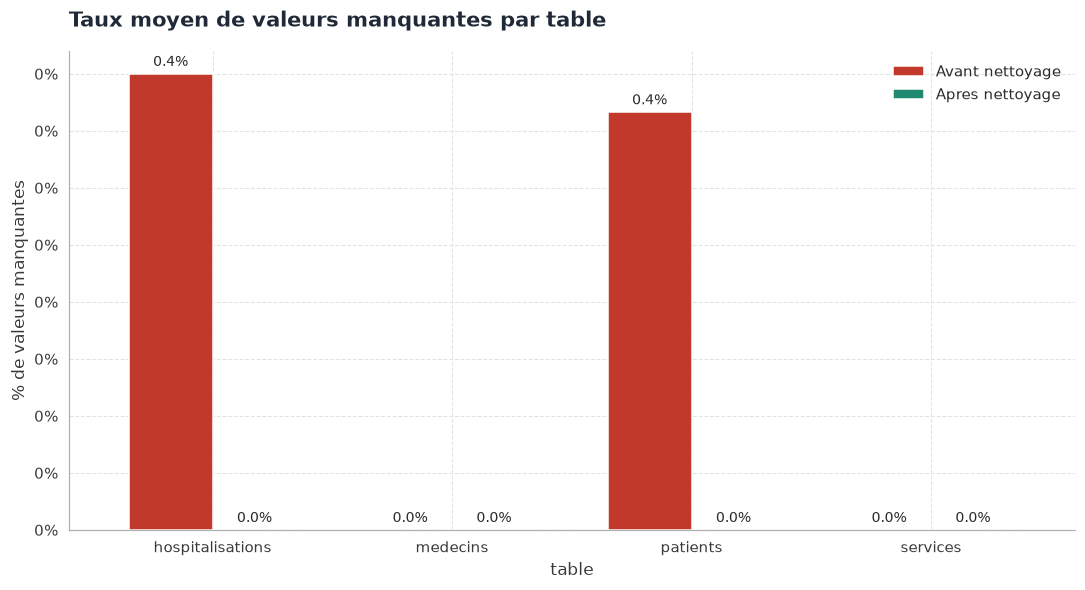

In [19]:
completude_moy_avant = completude_avant.groupby("table")["taux_manquant_pct"].mean().rename("Avant nettoyage")
completude_moy_apres = completude_apres.groupby("table")["taux_manquant_pct"].mean().rename("Apres nettoyage")
comparatif_completude = pd.concat([completude_moy_avant, completude_moy_apres], axis=1).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5.5))
comparatif_completude.plot(kind="bar", color=[COULEUR_AVANT, COULEUR_APRES], width=0.7, ax=ax, edgecolor="white")
etiqueter_barres(ax, fmt="{:.1f}%")
styliser_axe(ax, "Taux moyen de valeurs manquantes par table", ylabel="% de valeurs manquantes")
plt.xticks(rotation=0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
plt.tight_layout()
plt.show()

### 7.2 Doublons détectés par table

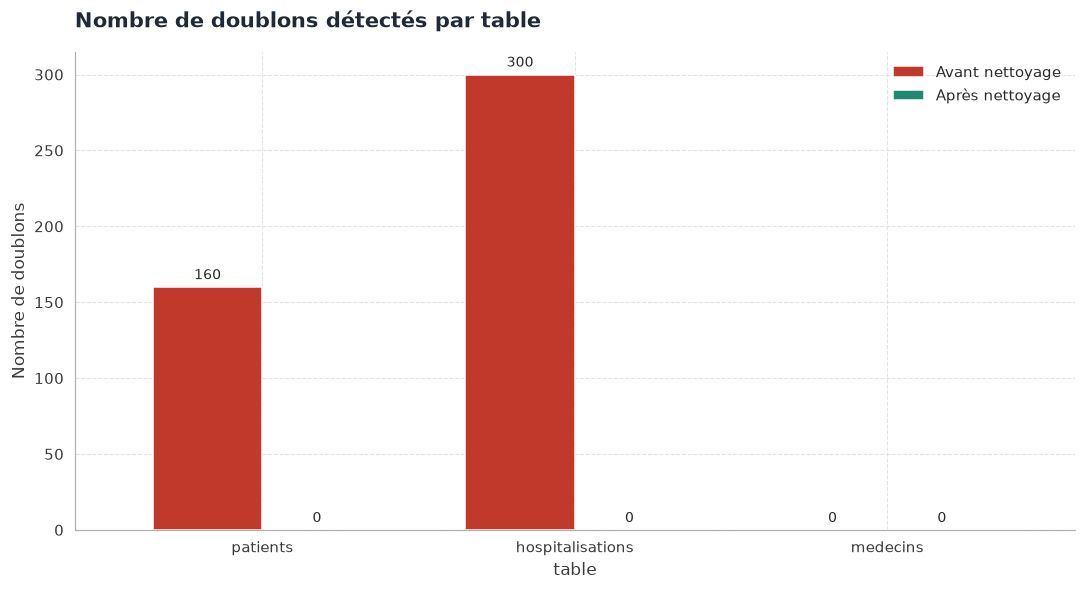

In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5))
recap_doublons.set_index("table")[["nb_doublons_avant", "nb_doublons_apres"]].plot(
    kind="bar", color=[COULEUR_AVANT, COULEUR_APRES], width=0.7, ax=ax, edgecolor="white"
)
etiqueter_barres(ax, fmt="{:.0f}")
styliser_axe(ax, "Nombre de doublons détectés par table", ylabel="Nombre de doublons",
             legende=["Avant nettoyage", "Après nettoyage"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.3 Anomalies de cohérence par contrôle

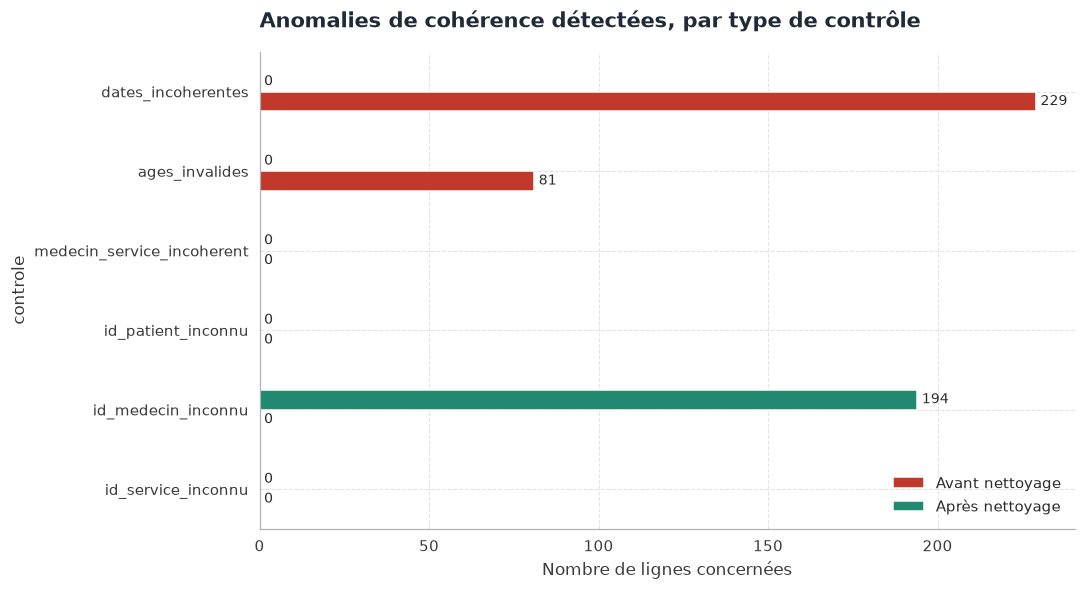

In [21]:
recap_coherence_tri = recap_coherence.set_index("controle")[["avant", "apres"]].sort_values("avant")

fig, ax = plt.subplots(figsize=(10, 5.5))
recap_coherence_tri.plot(kind="barh", color=[COULEUR_AVANT, COULEUR_APRES], ax=ax, edgecolor="white")
etiqueter_barres(ax, fmt="{:.0f}")
styliser_axe(ax, "Anomalies de cohérence détectées, par type de contrôle", xlabel="Nombre de lignes concernées",
             legende=["Avant nettoyage", "Après nettoyage"])
plt.tight_layout()
plt.show()

### 7.4 Volumétrie conservée vs supprimée

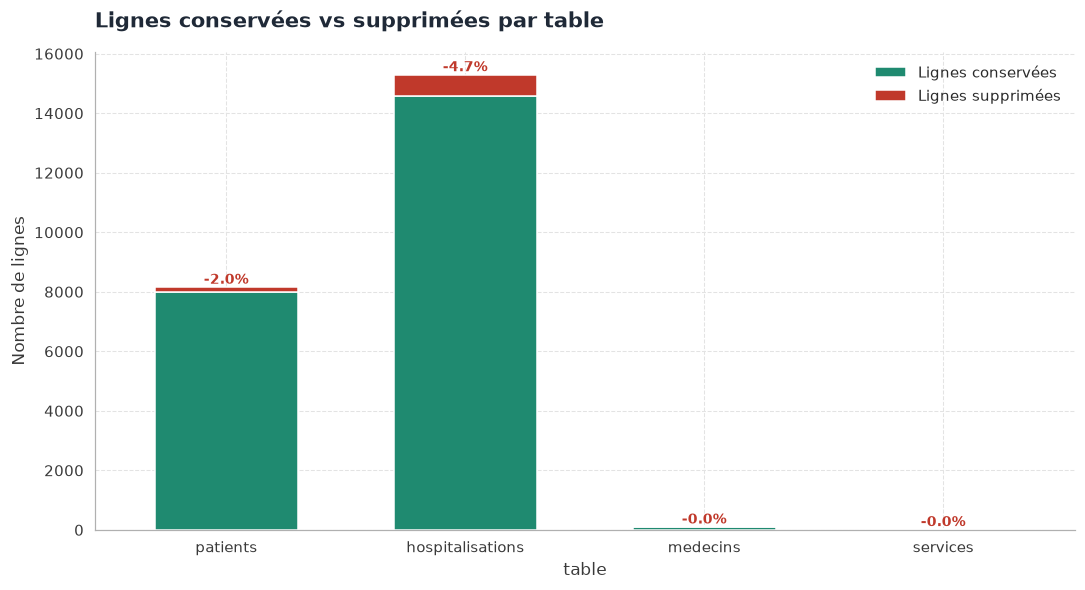

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.5))
recap_lignes.set_index("table")[["nb_lignes_apres", "lignes_supprimees"]].plot(
    kind="bar", stacked=True, color=[COULEUR_APRES, COULEUR_AVANT], width=0.6, ax=ax, edgecolor="white"
)
for i, row in recap_lignes.reset_index(drop=True).iterrows():
    ax.annotate(f"-{row['pct_supprime']:.1f}%", xy=(i, row["nb_lignes_avant"]),
                ha="center", va="bottom", fontsize=9, color=COULEUR_AVANT, fontweight="bold")
styliser_axe(ax, "Lignes conservées vs supprimées par table", ylabel="Nombre de lignes",
             legende=["Lignes conservées", "Lignes supprimées"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interprétation des graphiques 7.1 à 7.4 :** ces quatre visualisations racontent la même histoire sous des angles complémentaires. Le graphique 7.1 montre que la complétude s'améliore sur les tables qui contenaient des valeurs manquantes injectées, sans dégrader les tables déjà complètes. Le graphique 7.2 confirme la disparition totale des doublons après nettoyage. Le graphique 7.3, trié du contrôle le moins problématique au plus problématique, met en évidence les anomalies de cohérence les plus fréquentes (souvent les FK manquantes, qui découlent directement des valeurs nulles injectées dans `id_service`/`id_medecin`). Le graphique 7.4 traduit tout cela en un seul repère : le pourcentage de lignes perdues par table, qui doit rester limité si la stratégie de nettoyage est bien calibrée.

### 7.5 Répartition des anomalies détectées avant nettoyage

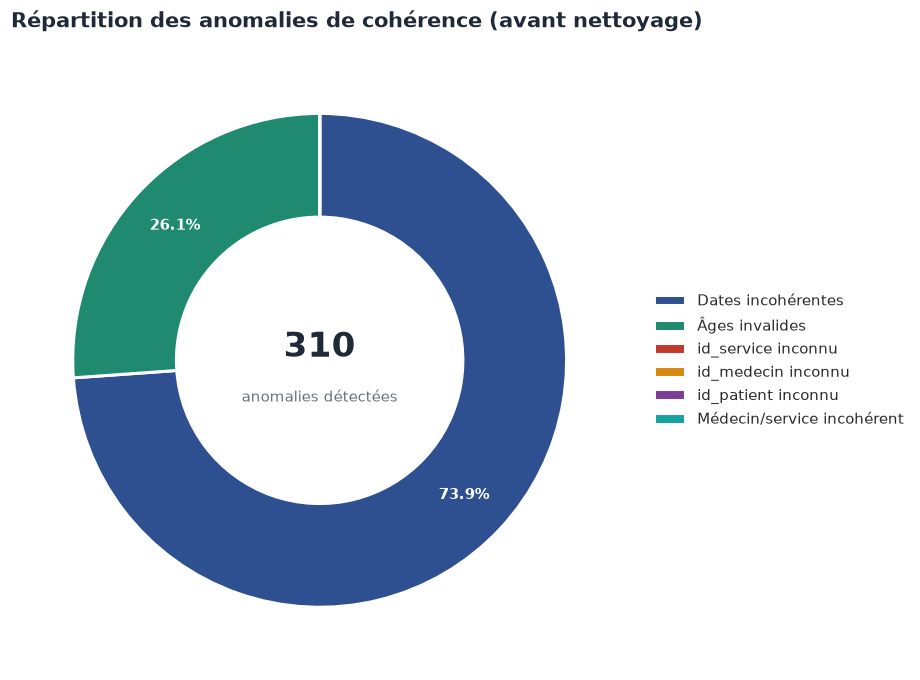

In [23]:
anomalies_series = pd.Series(coherence_avant).sort_values(ascending=False)
total_anomalies = anomalies_series.sum()

libelles = {
    "dates_incoherentes": "Dates incohérentes",
    "id_service_inconnu": "id_service inconnu",
    "id_medecin_inconnu": "id_medecin inconnu",
    "id_patient_inconnu": "id_patient inconnu",
    "medecin_service_incoherent": "Médecin/service incohérent",
    "ages_invalides": "Âges invalides",
}
anomalies_series.index = [libelles.get(i, i) for i in anomalies_series.index]

fig, ax = plt.subplots(figsize=(8.5, 8.5))
wedges, _, autotexts = ax.pie(
    anomalies_series,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p > 3 else "",
    startangle=90,
    counterclock=False,
    colors=PALETTE_CATEGORIELLE,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    pctdistance=0.80,
)
plt.setp(autotexts, size=10, color="white", fontweight="bold")

ax.text(0, 0.05, f"{total_anomalies:,}".replace(",", " "), ha="center", va="center",
        fontsize=22, fontweight="bold", color="#1F2937")
ax.text(0, -0.15, "anomalies détectées", ha="center", va="center", fontsize=10, color="#6B7280")

ax.legend(wedges, anomalies_series.index, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
ax.set_title("Répartition des anomalies de cohérence (avant nettoyage)", loc="left", fontsize=14,
             fontweight="bold", color="#1F2937", pad=16)
plt.tight_layout()
plt.show()

### 7.6 Causes de suppression des lignes (hospitalisations)

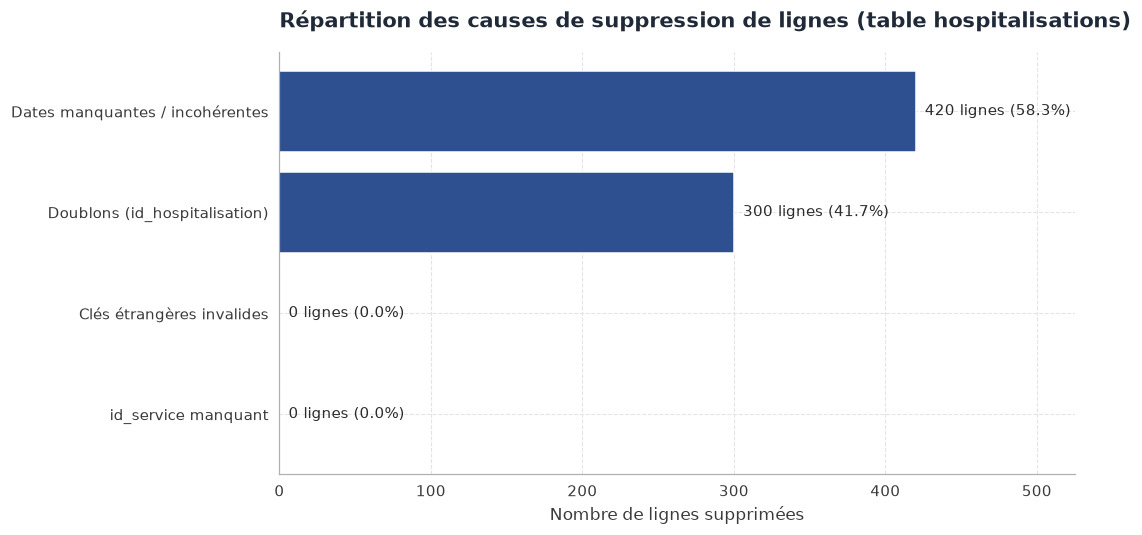

In [24]:
causes_suppression = pd.DataFrame({
    "cause": [
        "Doublons (id_hospitalisation)",
        "id_service manquant",
        "Dates manquantes / incohérentes",
        "Clés étrangères invalides",
    ],
    "lignes_supprimees": [n_doublons_hosp_supprimes, n_supprime_service, n_supprime_dates, n_supprime_fk],
}).sort_values("lignes_supprimees")
causes_suppression["part_pct"] = (
    causes_suppression["lignes_supprimees"] / causes_suppression["lignes_supprimees"].sum() * 100
).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
barres = ax.barh(causes_suppression["cause"], causes_suppression["lignes_supprimees"],
                  color=COULEUR_ACCENT, edgecolor="white")
for barre, part in zip(barres, causes_suppression["part_pct"]):
    ax.annotate(f"{int(barre.get_width())} lignes ({part}%)",
                xy=(barre.get_width(), barre.get_y() + barre.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9.5, color="#2B2B2B")

styliser_axe(ax, "Répartition des causes de suppression de lignes (table hospitalisations)",
             xlabel="Nombre de lignes supprimées")
ax.set_xlim(0, causes_suppression["lignes_supprimees"].max() * 1.25)
plt.tight_layout()
plt.show()

**Interprétation (7.5 et 7.6) :** le graphique en anneau (7.5) montre le poids relatif de chaque type d'anomalie détectée avant nettoyage — utile pour prioriser les efforts si le pipeline devait être industrialisé. Le graphique 7.6 va plus loin en isolant, pour la seule table `hospitalisations`, la cause exacte de chaque ligne supprimée pendant le nettoyage. Cette décomposition permet de répondre à une question fréquente en soutenance : « pourquoi telle proportion de lignes a-t-elle été supprimée ? » — la réponse est ici directement lisible et quantifiée cause par cause, plutôt que noyée dans un taux global.

### 7.7 Distribution de la durée de séjour (données nettoyées)

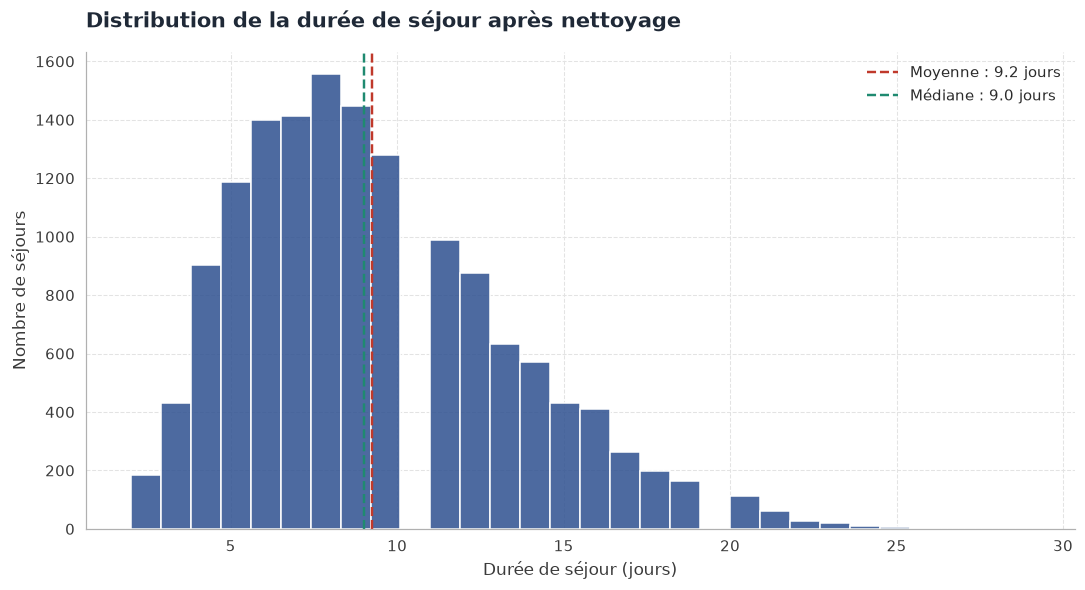

In [25]:
df_hospitalisations_clean["duree_sejour"] = (
    df_hospitalisations_clean["date_sortie"] - df_hospitalisations_clean["date_entree"]
).dt.days

moyenne_duree = df_hospitalisations_clean["duree_sejour"].mean()
mediane_duree = df_hospitalisations_clean["duree_sejour"].median()

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(df_hospitalisations_clean["duree_sejour"], bins=30, color=COULEUR_ACCENT,
             edgecolor="white", alpha=0.85, ax=ax)
ax.axvline(moyenne_duree, color=COULEUR_AVANT, linestyle="--", linewidth=1.6,
           label=f"Moyenne : {moyenne_duree:.1f} jours")
ax.axvline(mediane_duree, color=COULEUR_APRES, linestyle="--", linewidth=1.6,
           label=f"Médiane : {mediane_duree:.1f} jours")

styliser_axe(ax, "Distribution de la durée de séjour après nettoyage",
             xlabel="Durée de séjour (jours)", ylabel="Nombre de séjours", legende=None)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Interprétation :** ce graphique n'audite plus la qualité des données, il en démontre l'exploitabilité. La durée de séjour (`duree_sejour`) est une variable dérivée qui n'existe pas dans les fichiers bruts et qui n'a pu être calculée de façon fiable qu'une fois les dates manquantes ou incohérentes écartées à l'étape 4.7 : c'est un bon exemple concret de la valeur ajoutée du nettoyage. La comparaison moyenne/médiane renseigne aussi sur la forme de la distribution : un écart important entre les deux indique une distribution asymétrique, tirée vers la droite par quelques séjours de longue durée (cas typiques en réanimation ou en oncologie).

### 7.8 Tableau de bord de synthèse

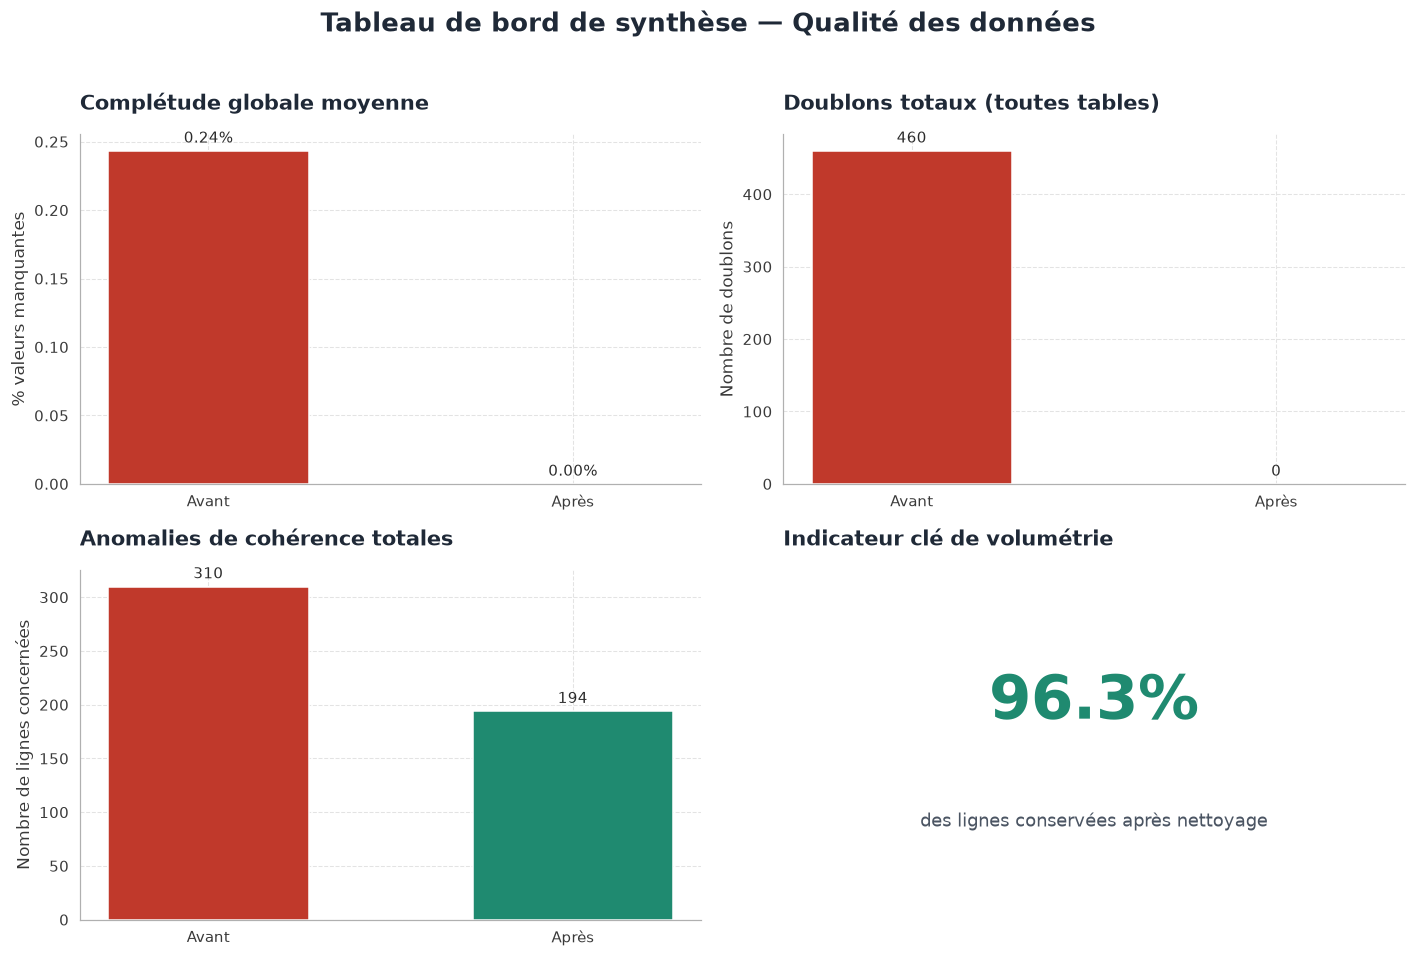

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
ax1, ax2, ax3, ax4 = axes.flat

# -- Panneau 1 : complétude globale --
completude_globale = pd.Series({
    "Avant": completude_avant["taux_manquant_pct"].mean(),
    "Après": completude_apres["taux_manquant_pct"].mean(),
})
barres1 = ax1.bar(completude_globale.index, completude_globale.values,
                   color=[COULEUR_AVANT, COULEUR_APRES], width=0.55, edgecolor="white")
ax1.bar_label(barres1, fmt="%.2f%%", padding=3, fontsize=10)
styliser_axe(ax1, "Complétude globale moyenne", ylabel="% valeurs manquantes")

# -- Panneau 2 : doublons totaux --
doublons_totaux = pd.Series({
    "Avant": recap_doublons["nb_doublons_avant"].sum(),
    "Après": recap_doublons["nb_doublons_apres"].sum(),
})
barres2 = ax2.bar(doublons_totaux.index, doublons_totaux.values,
                   color=[COULEUR_AVANT, COULEUR_APRES], width=0.55, edgecolor="white")
ax2.bar_label(barres2, fmt="%.0f", padding=3, fontsize=10)
styliser_axe(ax2, "Doublons totaux (toutes tables)", ylabel="Nombre de doublons")

# -- Panneau 3 : anomalies de coherence totales --
coherence_totale = pd.Series({
    "Avant": recap_coherence["avant"].sum(),
    "Après": recap_coherence["apres"].sum(),
})
barres3 = ax3.bar(coherence_totale.index, coherence_totale.values,
                   color=[COULEUR_AVANT, COULEUR_APRES], width=0.55, edgecolor="white")
ax3.bar_label(barres3, fmt="%.0f", padding=3, fontsize=10)
styliser_axe(ax3, "Anomalies de cohérence totales", ylabel="Nombre de lignes concernées")

# -- Panneau 4 : indicateur cle (KPI) lignes conservees --
pct_conserve = recap_lignes["nb_lignes_apres"].sum() / recap_lignes["nb_lignes_avant"].sum() * 100
couleur_kpi = COULEUR_APRES if pct_conserve >= 95 else ("#D68910" if pct_conserve >= 90 else COULEUR_AVANT)
ax4.axis("off")
ax4.text(0.5, 0.62, f"{pct_conserve:.1f}%", ha="center", va="center",
         fontsize=40, fontweight="bold", color=couleur_kpi, transform=ax4.transAxes)
ax4.text(0.5, 0.28, "des lignes conservées après nettoyage", ha="center", va="center",
         fontsize=12, color="#4B5563", transform=ax4.transAxes)
ax4.set_title("Indicateur clé de volumétrie", loc="left", fontsize=14, fontweight="bold", color="#1F2937")

for ax in (ax1, ax2, ax3):
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Tableau de bord de synthèse — Qualité des données", fontsize=17, fontweight="bold",
             color="#1F2937", y=1.02)
plt.tight_layout()
plt.show()

**Interprétation :** ce tableau de bord condense en une seule figure les quatre indicateurs qui résument le mieux l'impact du nettoyage : complétude globale, doublons, anomalies de cohérence, et volumétrie conservée. C'est la visualisation à privilégier en ouverture ou en conclusion d'un rapport de qualité de données, car elle permet de juger en un coup d'œil si le nettoyage a été efficace, avant de dérouler le détail table par table présenté dans les graphiques 7.1 à 7.6. Le code couleur du dernier indicateur (vert / orange / rouge selon le seuil de lignes conservées) peut être ajusté selon le niveau d'exigence attendu par le projet.

## 8. Export des fichiers nettoyés et du rapport qualité

In [27]:
df_patients_clean.to_csv(f"{CLEAN_DIR}/patients.csv", index=False)
df_services_clean.to_csv(f"{CLEAN_DIR}/services.csv", index=False)
df_medecins_clean.to_csv(f"{CLEAN_DIR}/medecins.csv", index=False)
df_hospitalisations_clean.to_csv(f"{CLEAN_DIR}/hospitalisations.csv", index=False)

recap_lignes.to_csv(f"{CLEAN_DIR}/rapport_qualite_lignes.csv", index=False)
recap_coherence.to_csv(f"{CLEAN_DIR}/rapport_qualite_coherence.csv", index=False)
recap_doublons.to_csv(f"{CLEAN_DIR}/rapport_qualite_doublons.csv", index=False)

print("Fichiers nettoyes exportes dans data/clean/")
print(f"- patients.csv : {len(df_patients_clean)} lignes")
print(f"- services.csv : {len(df_services_clean)} lignes")
print(f"- medecins.csv : {len(df_medecins_clean)} lignes")
print(f"- hospitalisations.csv : {len(df_hospitalisations_clean)} lignes")

Fichiers nettoyes exportes dans data/clean/
- patients.csv : 8000 lignes
- services.csv : 16 lignes
- medecins.csv : 103 lignes
- hospitalisations.csv : 14580 lignes


---
### Récapitulatif du livrable "Rapport qualité"

Pour ton rapport de stage / soutenance, tu peux directement réutiliser :
- Le tableau `recap_lignes` (volumes avant/après)
- Le tableau `recap_coherence` (anomalies avant/après)
- Le tableau `recap_doublons` (doublons avant/après)
- Les 8 visualisations de la section 7, en particulier le tableau de bord de synthèse (7.8) pour une slide de conclusion et le donut (7.5) ou le graphique des causes de suppression (7.6) pour une slide de détail

Pour exporter une figure en image (PNG haute résolution, réutilisable dans un PDF/Word/PowerPoint), ajouter avant chaque `plt.show()` :
```python
plt.savefig(f"{FIG_DIR}/nom_du_graphique.png", bbox_inches="tight")
```

### Prochaine étape
Ouvrir `03_etl_chargement_dwh.ipynb` pour transformer ces données propres et les charger dans le Data Warehouse MySQL (schéma étoile).